# 01 - Connectome QC And Motif Census

## Purpose

This is the intake notebook for a new dataset. It verifies that `mij_matrix.csv` and `mij_netlist.csv` agree, confirms the E/I labels and basic matrix structure, and produces the baseline directed triad census that the downstream notebooks reuse.

## Inputs

- `mij_matrix.csv`: square signed directed matrix, indexed as `A[pre, post]`.
- `mij_netlist.csv`: long-form edge list with `pre_neuron`, `post_neuron`, `pre_ei`, `post_ei`, and `m_ij`.

## Outputs

Tables are written to `outputs/consolidated_01_qc_census/`:

- `qc_summary.csv`
- `triad_census.csv`
- `node_triad_participation.csv`

In [1]:
from IPython.display import Image, display

from motif_workflow import ConnectomePaths, run_qc_and_census
from rees_figure7 import Figure7Config, run_figure7_analysis

paths = ConnectomePaths(
    matrix="mij_matrix.csv",
    netlist="mij_netlist.csv",
)

result = run_qc_and_census(paths)
print(f"Output directory: {result['output_dir'].resolve()}")

Output directory: C:\Users\ranic\Documents\GitHub\AscoliLab\motif_analysis\outputs\consolidated_01_qc_census


## Dataset Checks

In [2]:
display(result["qc_summary"])

,metric,value
0,matrix nodes,85
1,netlist rows,1641
2,nonzero matrix entries,1641
3,off-diagonal nonzero entries,1570
4,self-loop entries,71
5,excitatory labels,32
6,inhibitory labels,53
7,positive off-diagonal entries,707
8,negative off-diagonal entries,863
9,regions,9


## Directed Triad Census

This census uses the Davis-Holland-Leinhardt directed triad vocabulary. Self-loops are excluded from the triad enumeration so the census describes three distinct cell types.

In [3]:
display(result["triad_census"])

nonempty = result["triad_census"].query("count > 0")
print(f"Observed {len(nonempty)} of {len(result['triad_census'])} directed triad classes.")

Observed 16 of 16 directed triad classes.


,triad_class,count,share
0,003,30084,0.304586
1,012,29545,0.299129
2,102,20569,0.208251
3,021D,2811,0.028460
4,021U,1288,0.013040
5,021C,1644,0.016645
6,111D,1022,0.010347
7,111U,3376,0.034180
8,030T,2249,0.022770
9,030C,16,0.000162


## Node-Level Participation

In [4]:
participation = result["node_triad_participation"].copy()
triad_cols = [c for c in participation.columns if c not in {"cell_type", "ei"}]
participation["all_nonempty_triads"] = participation[triad_cols].sum(axis=1) - participation.get("003", 0)
display(participation.sort_values("all_nonempty_triads", ascending=False).head(20))

,cell_type,ei,003,012,102,021D,021U,021C,111D,111U,030T,030C,201,120D,120U,120C,210,300,all_nonempty_triads
46,CA3c Pyramidal,E,134,970,623,318,85,57,47,513,207,0,28,155,138,13,159,39,3352
30,CA2 Pyramidal,E,168,1283,299,648,103,106,30,162,319,1,1,203,94,23,37,9,3318
1,CA1 Back Projection,I,184,1102,548,429,86,73,47,311,222,0,2,105,141,36,140,60,3302
43,CA3 Pyramidal,E,324,1120,636,116,57,209,40,375,175,3,11,176,105,12,95,32,3162
18,CA1 Pyramidal,E,447,954,843,80,57,178,107,245,78,5,18,170,35,64,135,70,3039
75,MEC LII Stellate,E,453,1281,592,308,118,130,85,196,97,0,6,60,65,3,47,45,3033
45,CA3 Trilaminar,I,507,1511,362,292,104,84,27,89,215,0,3,151,86,7,40,8,2979
16,CA1 Perforant Path Associated,I,579,1222,442,140,124,227,73,151,210,6,4,109,75,45,62,17,2907
64,EC LIII Pyramidal,E,610,1048,835,72,149,100,96,239,80,0,24,59,36,8,59,71,2876
63,EC LII III Pyramidal Tripolar,E,651,1056,1024,24,77,80,56,230,35,0,24,39,53,4,37,96,2835


## Rees Figure 7: Structural Motif Profile

Reanalysis of [Rees et al. (2016), Figure 7](https://doi.org/10.1523/ENEURO.0205-16.2016) on the inputs above. Each unordered triple is counted once using all directed nonzero edges; weights, signs and self-loops are excluded. These are topology counts, not enrichment significance tests. The original 122-type connectome differs from this dataset.

### Regional And Cell-Group Assumptions

Panel C uses anatomical regions inferred from cell names, with LEC/MEC grouped as EC and CA3c as CA3; CA2 and SUB remain separate. Set `region_aliases={}` to keep all prefixes separate, or supply a metadata CSV with `cell_type`, `region`, and `ca1_group` to override assignments. That CSV must cover every cell type. Anatomical regions are a proxy for the paper's modules, not a detected community partition.

Panel D is an operational reconstruction: the default ratio compares **mean participation per cell type**, using triples entirely within CA1. The paper does not fully specify its normalization in the available text. Both raw totals and per-type ratios are exported. Set `ratio_scope="all_triads"` to include every triple containing each CA1 type, or `ratio_normalization="raw"` to plot total participation ratios.

Pyramidal defaults to `CA1 Pyramidal`. PST includes Axo Axonic, Horizontal Axo Axonic, Basket, Basket CCK+, and Horizontal Basket, following the paper. Other CA1 inhibitory types form the comparison group; unassigned types are reported. Missing groups and zero denominators produce gaps, not zeros. Review the exported node metadata before interpreting ratios.

In [5]:
figure7_config = Figure7Config(
    output_dir=paths.census_dir / "rees_figure7",
    ratio_scope="within_ca1",
    ratio_normalization="per_type",
    node_metadata=None,
)
figure7 = run_figure7_analysis(result, figure7_config)
print("\n".join(figure7["notes"]))

Rees Figure 7-style reanalysis; published numerical results are not reference inputs.
Binary A[pre,post] != 0, unordered distinct triples, induced edges, no self-loops.
Panel C uses supplied/inferred anatomical regions, not detected graph communities.
Panel D is an operational reconstruction; scope and normalization are explicit.
Ratios have no null model or significance interpretation. Zero denominators are missing, not zero.
1 CA1 types are unassigned and excluded from group ratios; review node_metadata.csv.


### A: Directed Motif Atlas
The Rees letters and standard DHL triad classes are shown together.

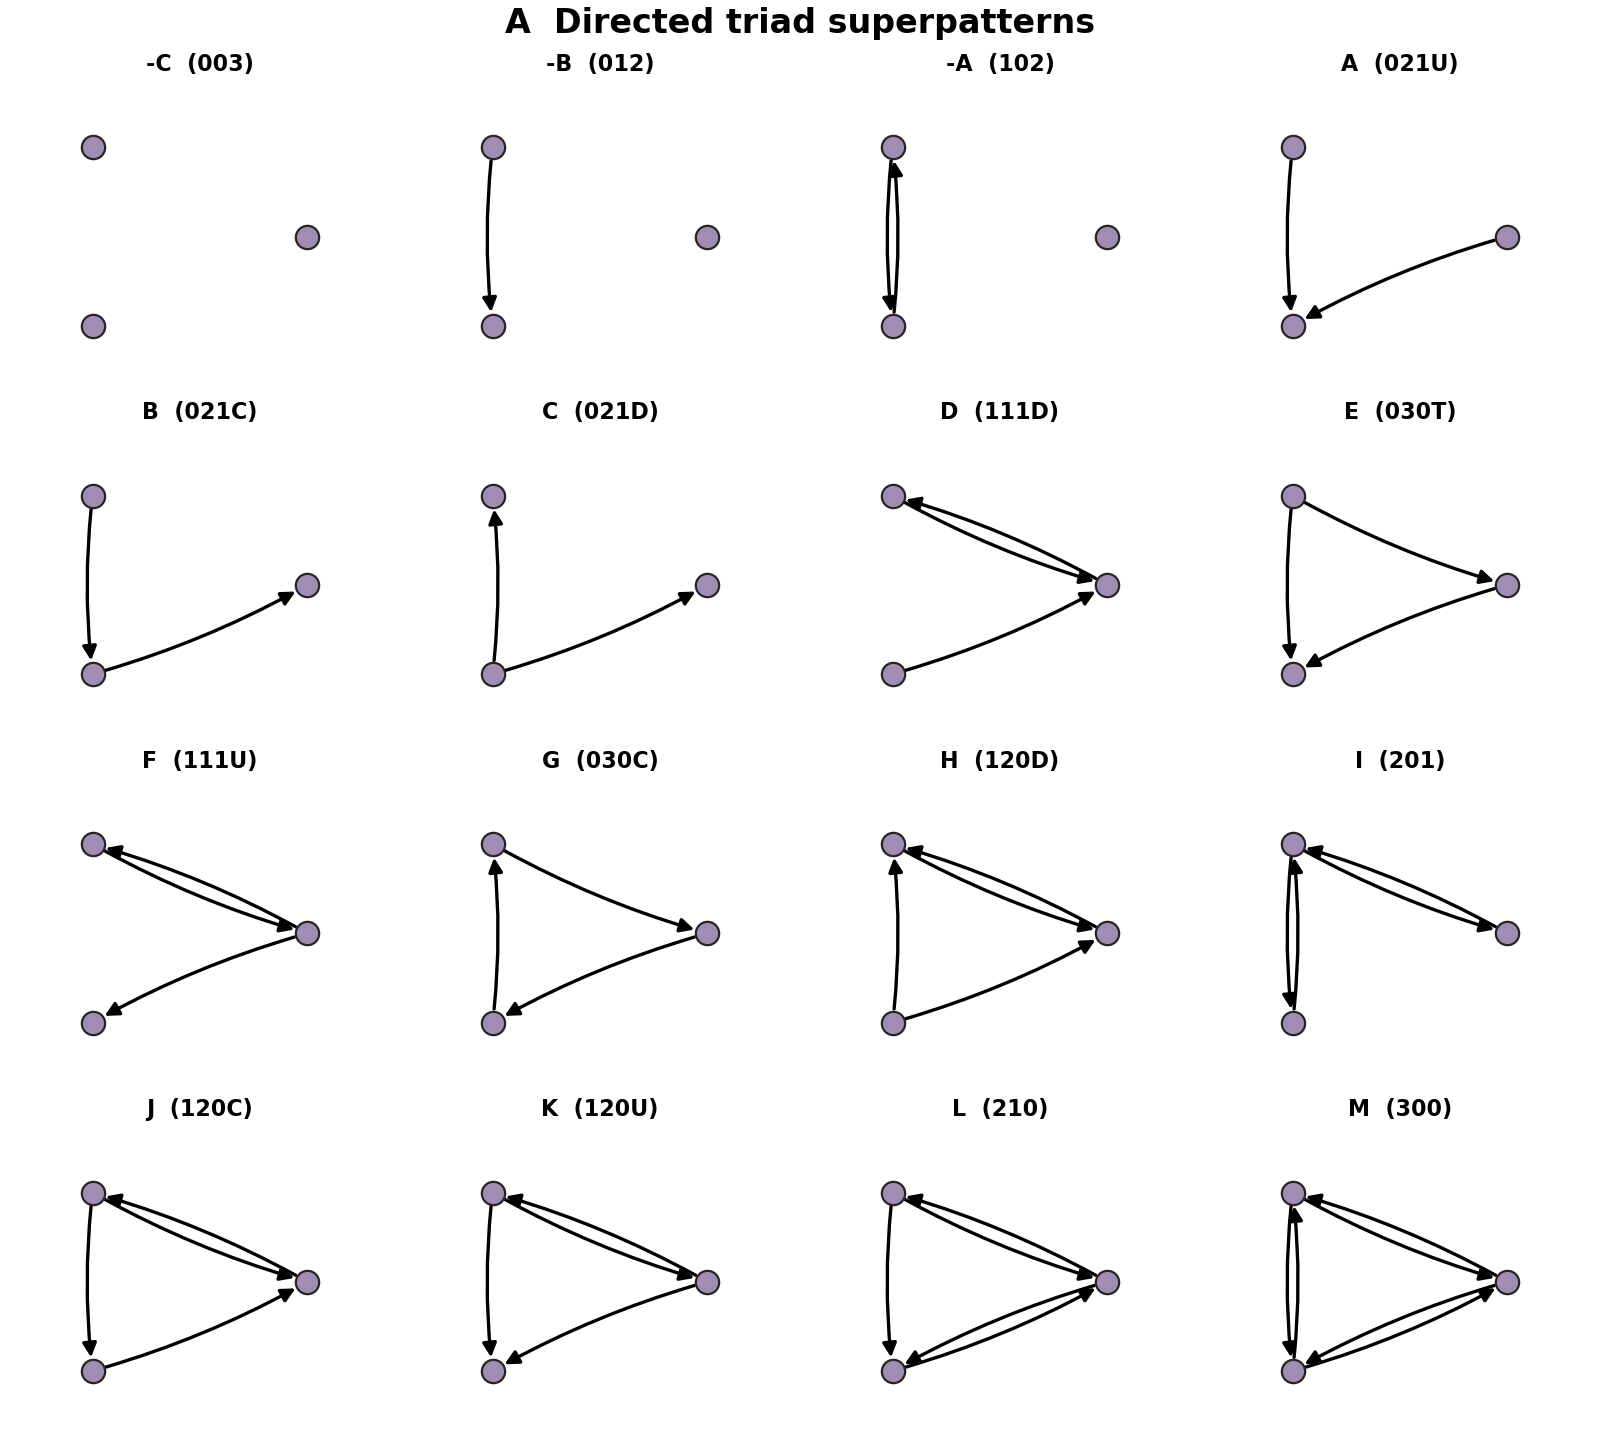

In [6]:
display(Image(filename=str(figure7["figure_paths"]["panel_a_atlas"]), width=850))

### B: Motif Frequencies
The pie includes all triples; the bars expand the connected classes. Counts reconcile with the census above.

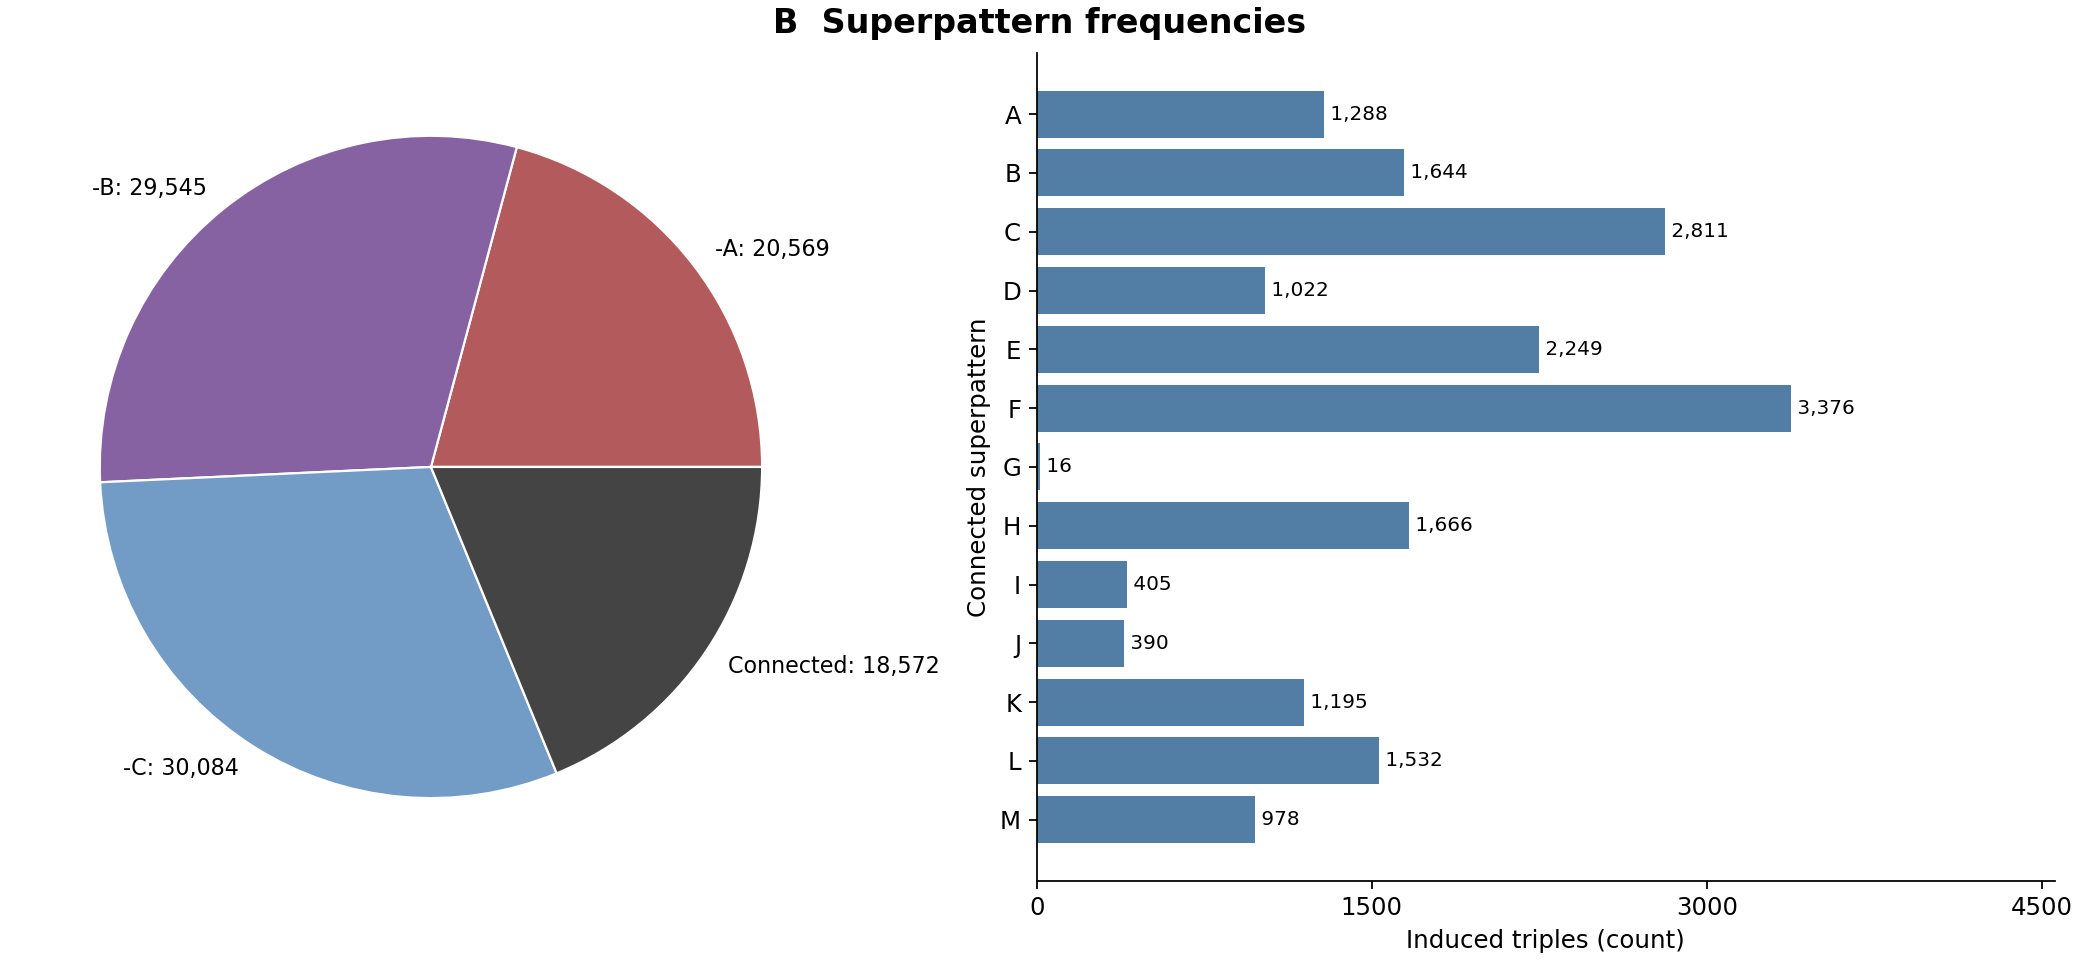

In [7]:
display(Image(filename=str(figure7["figure_paths"]["panel_b_counts"]), width=1000))

### C: Regional Utilization
A triple is intraregional only when all three cell types share the same assigned region. Each bar sums to 100%; absent motif classes are marked n=0.

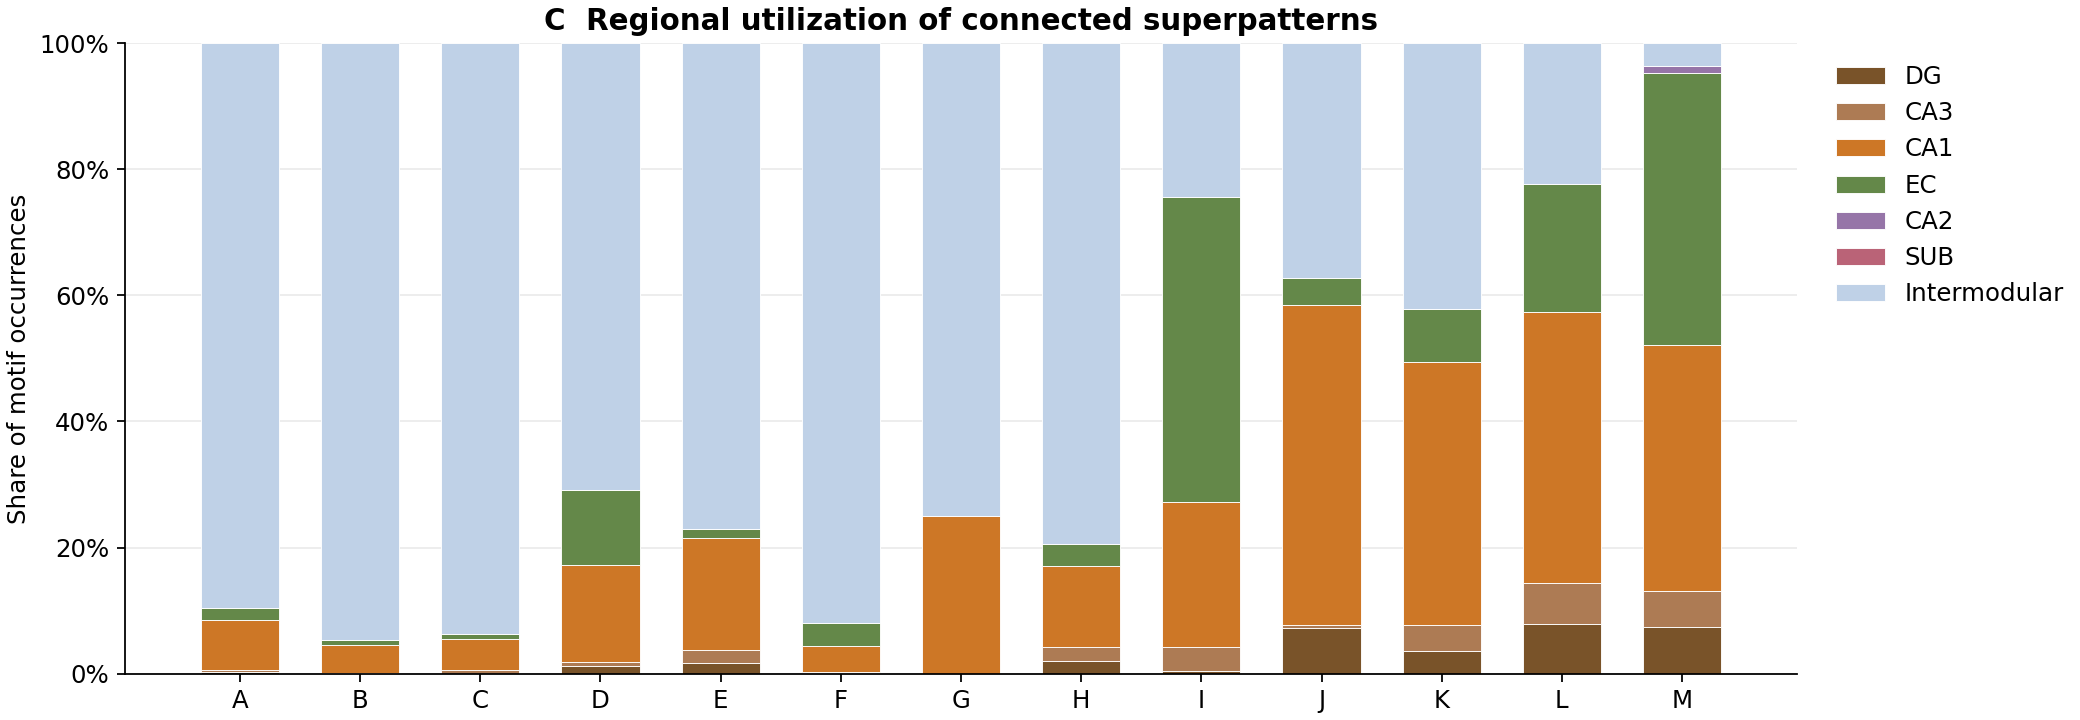

In [8]:
display(Image(filename=str(figure7["figure_paths"]["panel_c_regions"]), width=1000))

### D: CA1 Group Participation Ratios
Each occurrence credits all three participating cell types once. The horizontal line marks equal usage under the selected normalization; it is not a significance threshold.

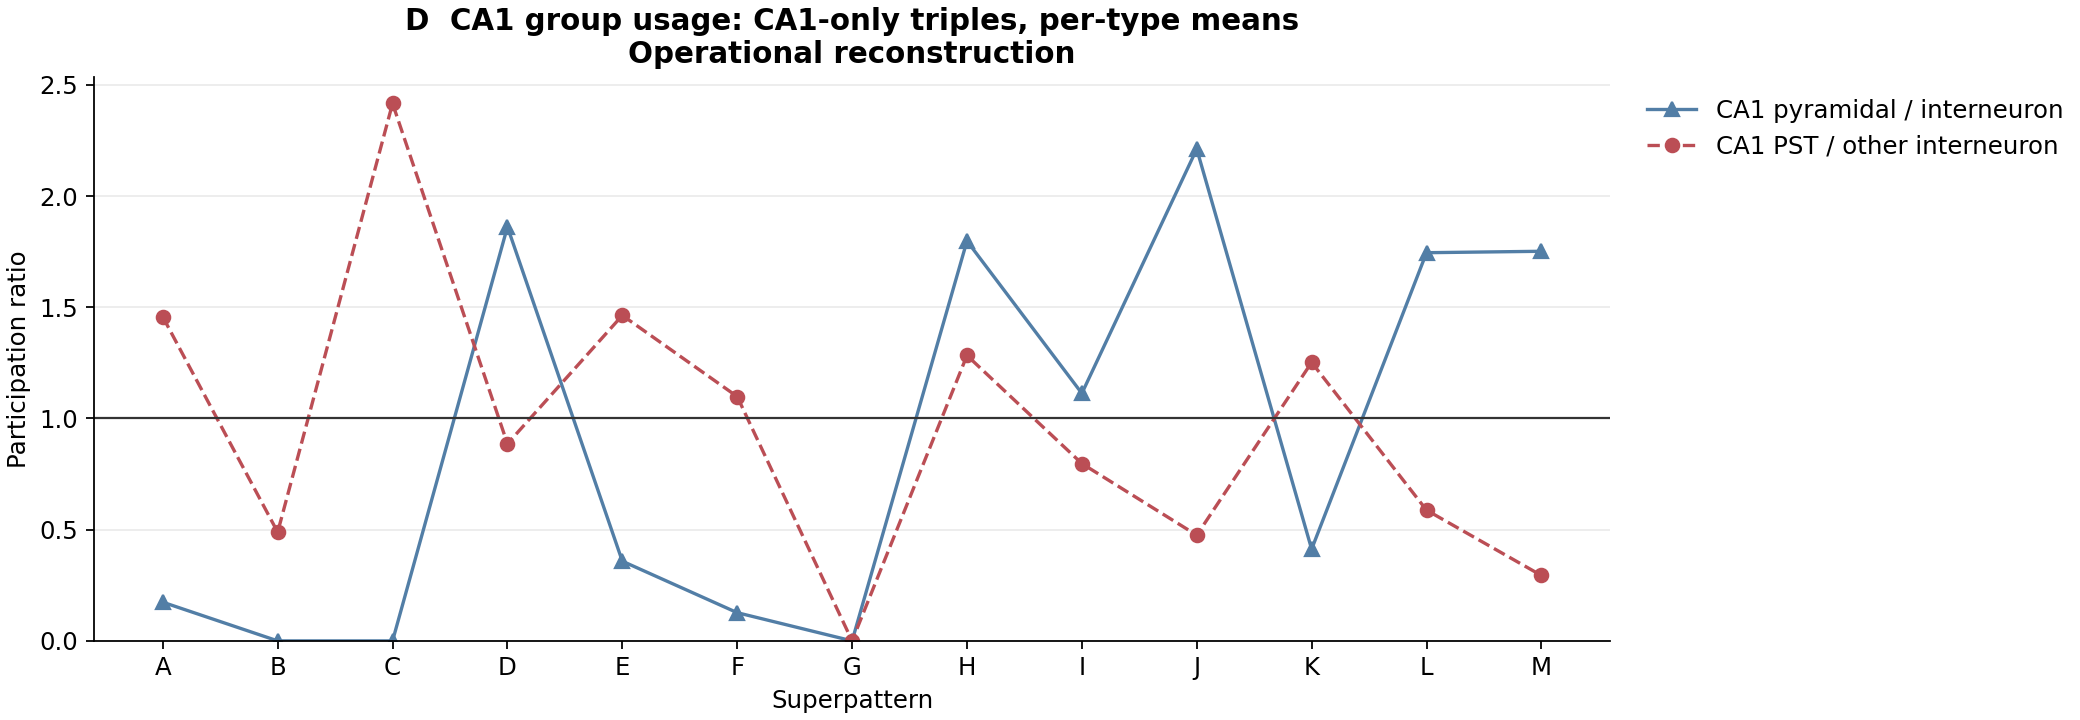

ca1_group
other_interneuron    21
pst                   5
pyramidal             1
unassigned            1
Name: cell_types, dtype: int64

In [9]:
display(Image(filename=str(figure7["figure_paths"]["panel_d_ca1_ratios"]), width=1000))
display(figure7["tables"]["node_metadata"].query("region == 'CA1'").groupby("ca1_group").size().rename("cell_types"))

### Node Participation Distribution
These supplementary views summarize connected induced triads across the entire dataset. Heatmap intensity is log(1 + count); exact counts are exported.

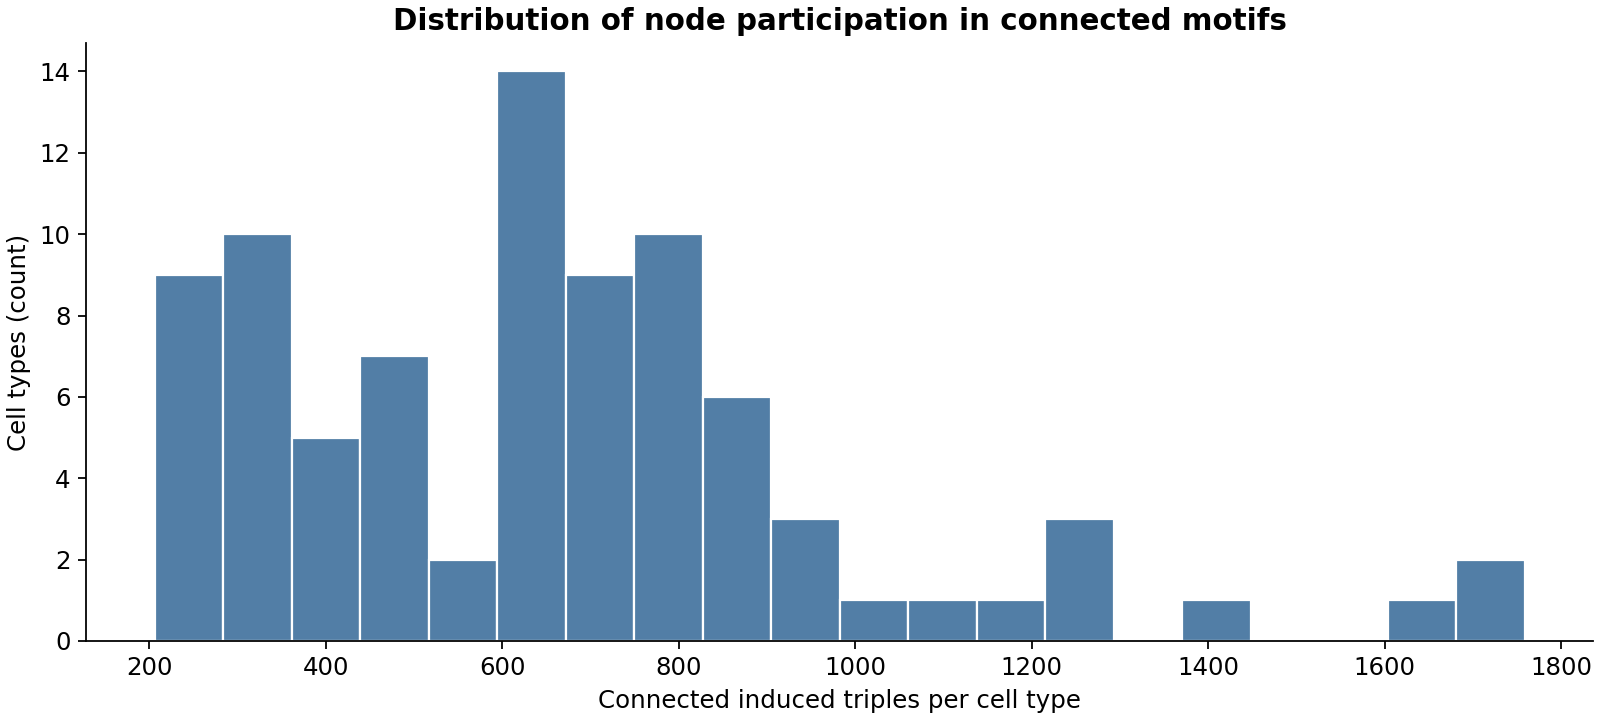

In [10]:
display(Image(filename=str(figure7["figure_paths"]["participation_histogram"]), width=900))

Tables, PNG/PDF panels, composite figure and input hashes: C:\Users\ranic\Documents\GitHub\AscoliLab\motif_analysis\outputs\consolidated_01_qc_census\rees_figure7


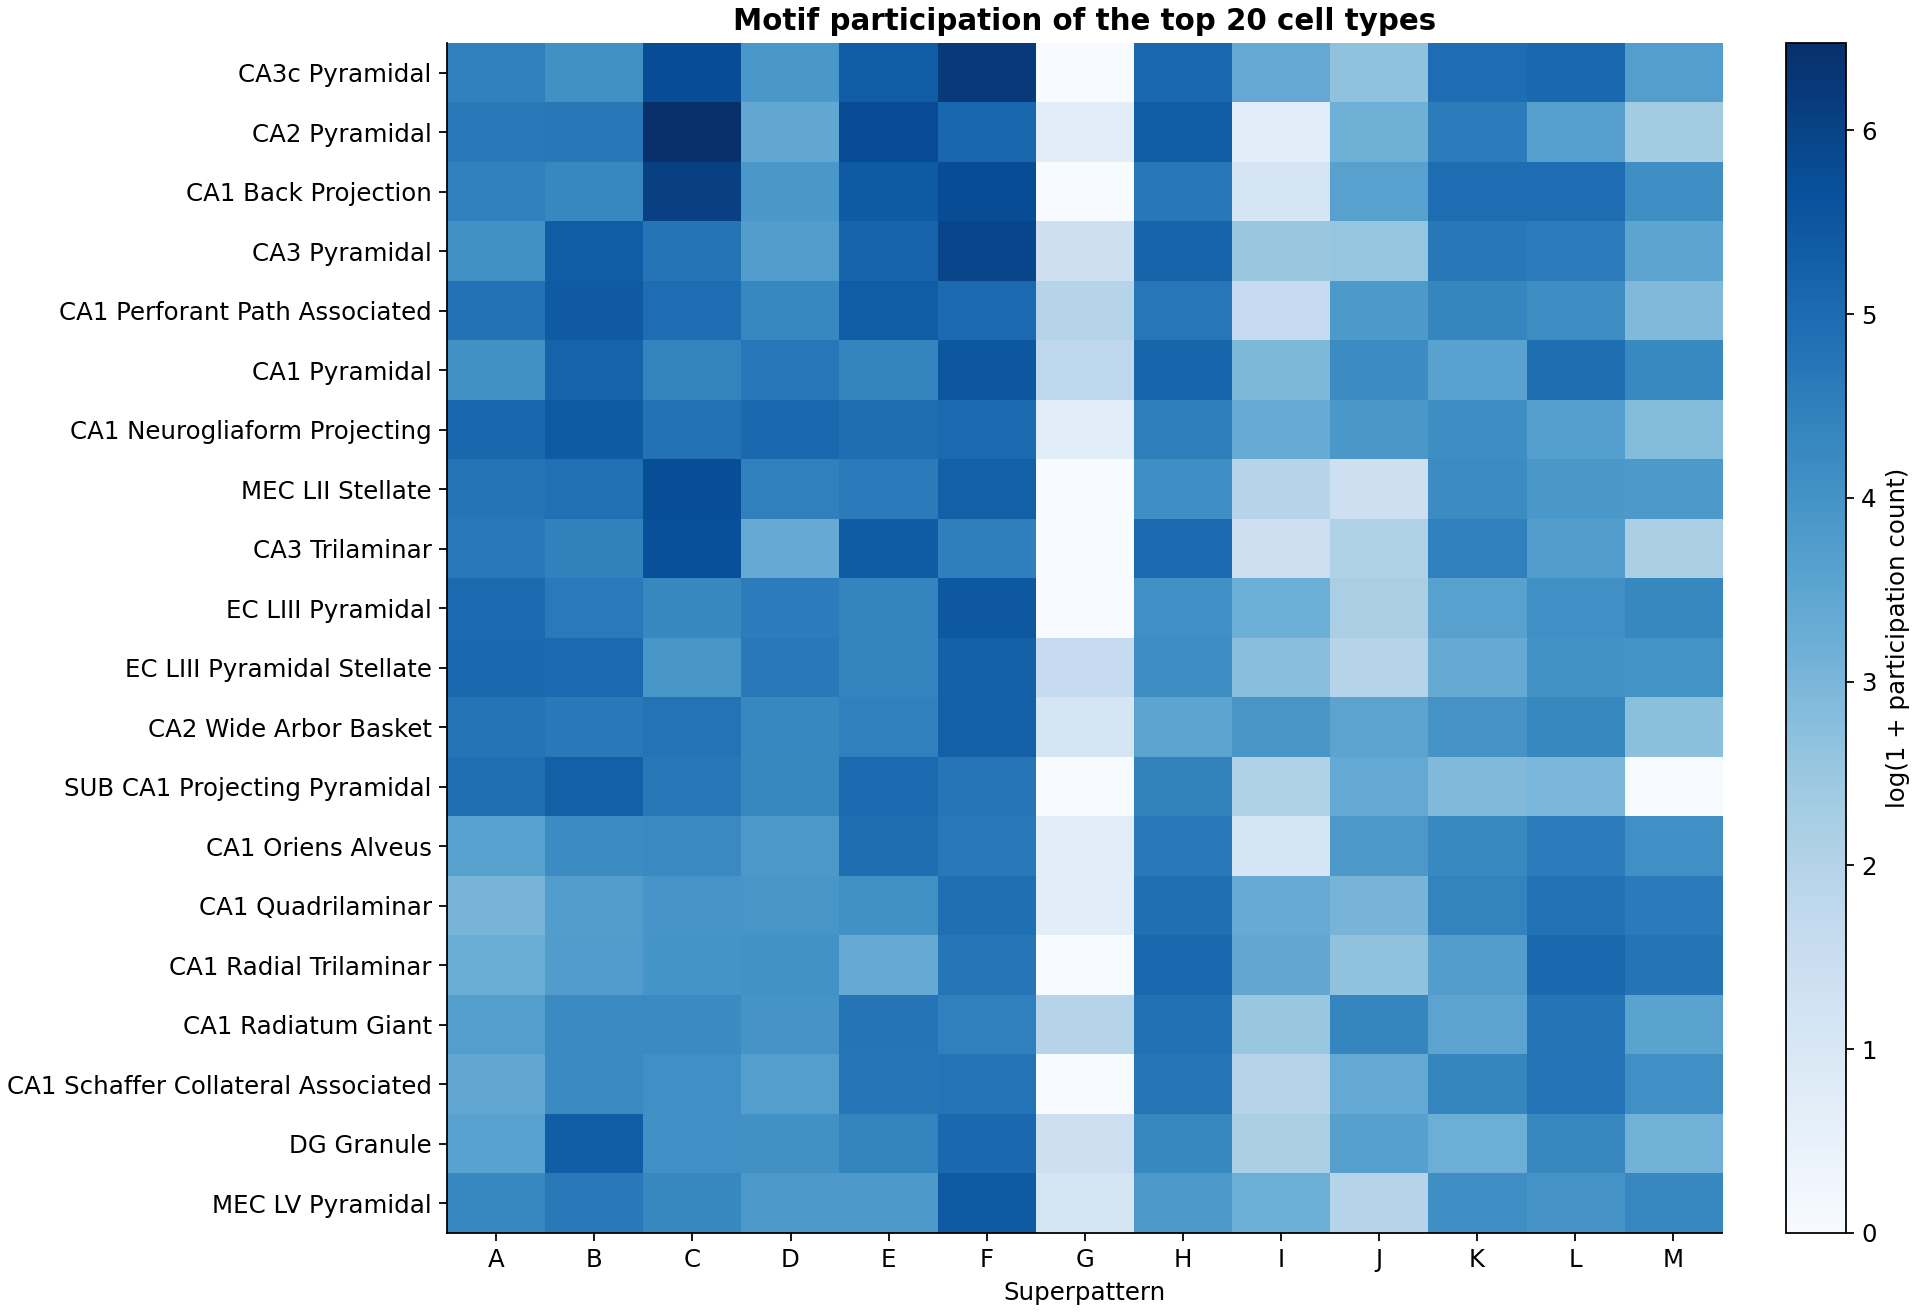

In [11]:
display(Image(filename=str(figure7["figure_paths"]["participation_heatmap"]), width=1000))
print(f"Tables, PNG/PDF panels, composite figure and input hashes: {figure7['output_dir'].resolve()}")

## Handoff To Notebook 02

Notebook 02 uses the same `mij_matrix.csv` and `mij_netlist.csv`, then adds weighted class-share null tests and E/I chain-signature analysis. The census here is the structural baseline; Notebook 02 asks whether the observed motif and chain organization is unusual under a null model.